In [2]:
from google.colab import files

uploaded = files.upload()

Saving image.jpg to image.jpg


In [2]:
import cv2

filename = next(iter(uploaded))
image = cv2.imread(filename)

print("Image loaded:", image is not None)
print("Image shape:", image.shape)

Image loaded: True
Image shape: (4187, 2817, 3)


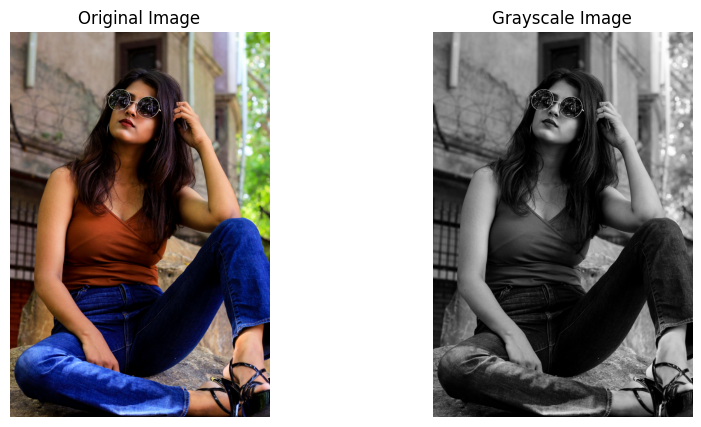

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


if image is None:
    raise ValueError("Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display original and grayscale
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

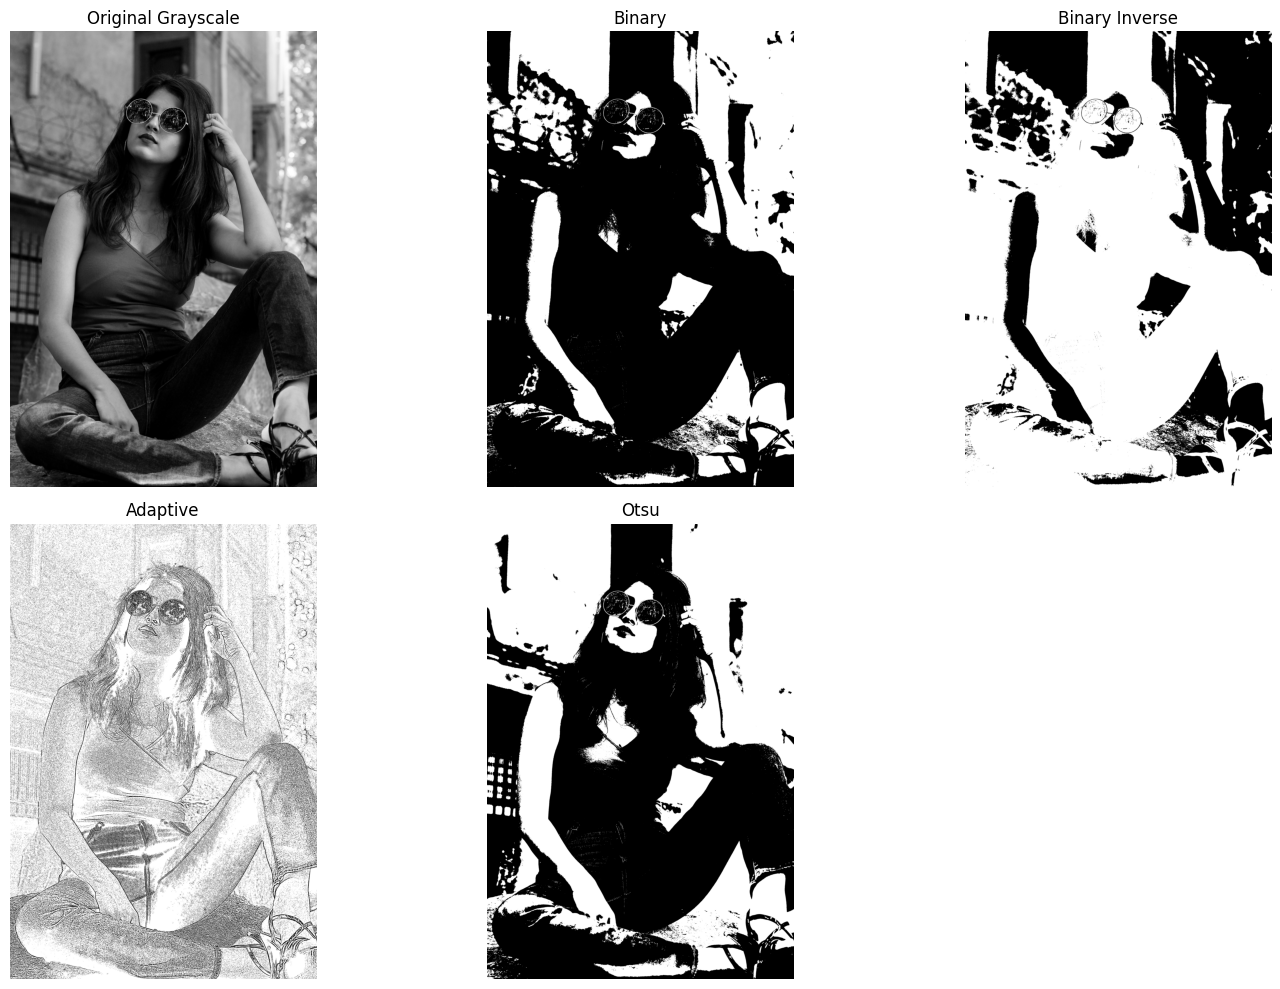

In [7]:
import cv2
import matplotlib.pyplot as plt

# Read image
image = cv2.imread("image.jpg")

if image is None:
    raise ValueError("Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Binary thresholding
_, binary = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Inverse thresholding
_, binary_inv = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY_INV
)

# Adaptive thresholding
adaptive = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)

# Otsu thresholding
_, otsu = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display results
images = [
    ("Original Grayscale", gray),
    ("Binary", binary),
    ("Binary Inverse", binary_inv),
    ("Adaptive", adaptive),
    ("Otsu", otsu)
]

plt.figure(figsize=(15, 10))

for i, (title, img) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

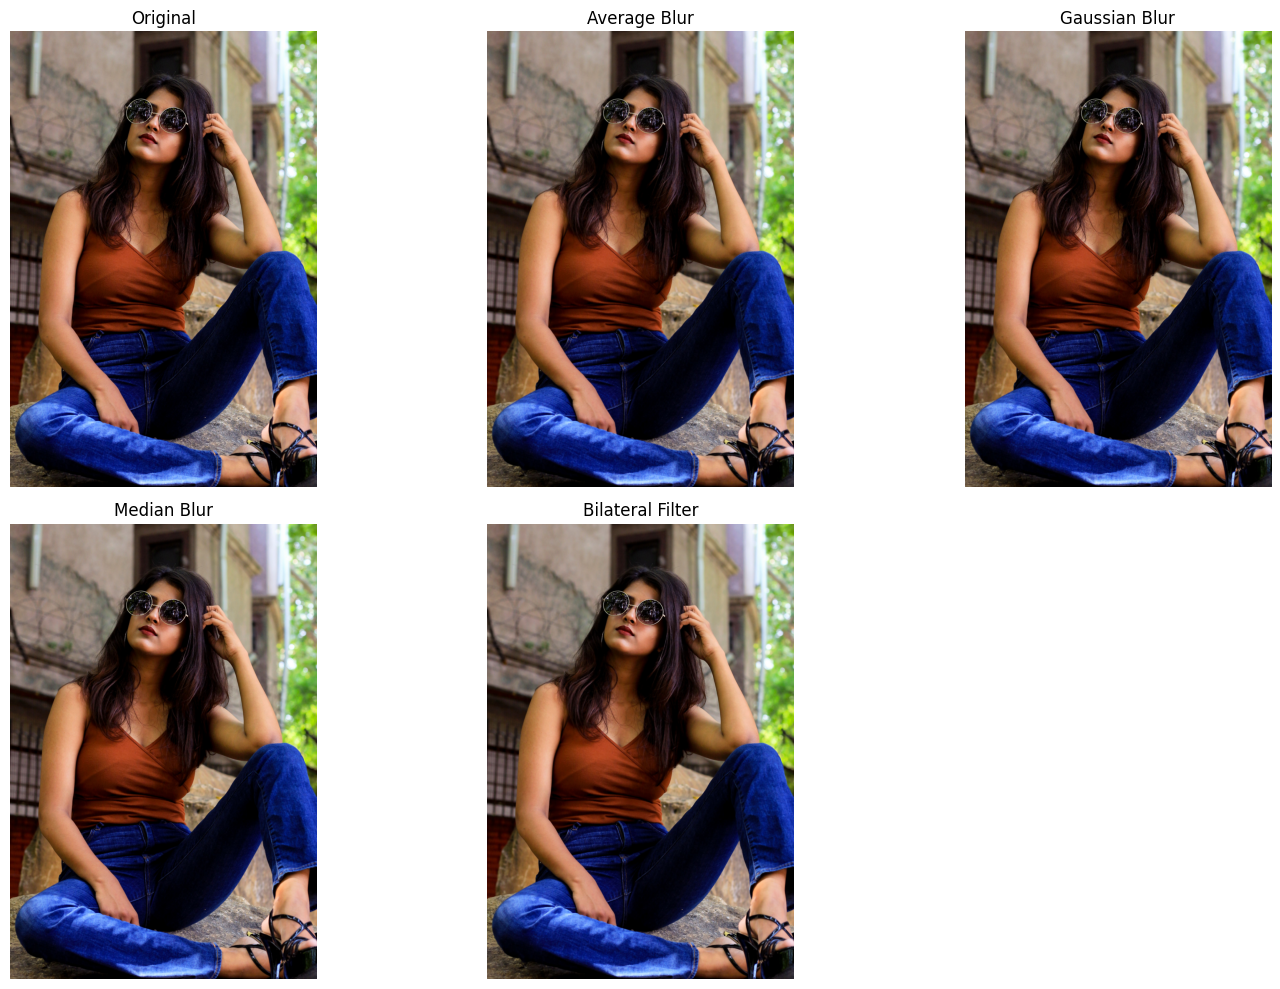

In [8]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("image.jpg")

if image is None:
    raise ValueError("Image not found!")

# Convert BGR to RGB for Matplotlib
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply filters
average = cv2.blur(image_rgb, (5, 5))

gaussian = cv2.GaussianBlur(
    image_rgb, (5, 5), 0
)

median = cv2.medianBlur(image_rgb, 5)

bilateral = cv2.bilateralFilter(
    image_rgb, 9, 75, 75
)

# Display comparison
images = [
    ("Original", image_rgb),
    ("Average Blur", average),
    ("Gaussian Blur", gaussian),
    ("Median Blur", median),
    ("Bilateral Filter", bilateral)
]

plt.figure(figsize=(15, 10))

for i, (title, img) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

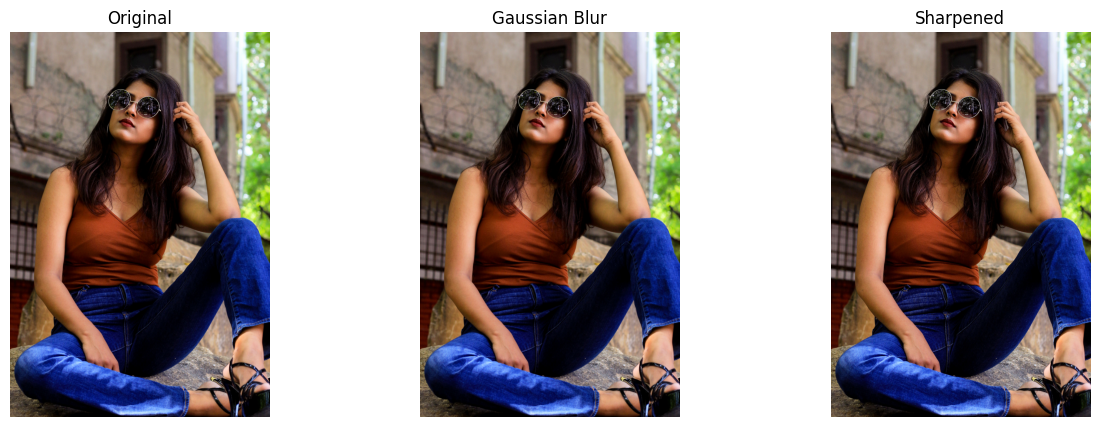

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
image = cv2.imread("image.jpg")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Gaussian Blur
blurred = cv2.GaussianBlur(image, (5, 5), 0)

# Sharpening
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(image, -1, kernel)

# Convert outputs to RGB
blurred_rgb = cv2.cvtColor(blurred, cv2.COLOR_BGR2RGB)
sharpened_rgb = cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB)

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred_rgb)
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened_rgb)
plt.title("Sharpened")
plt.axis("off")

plt.show()

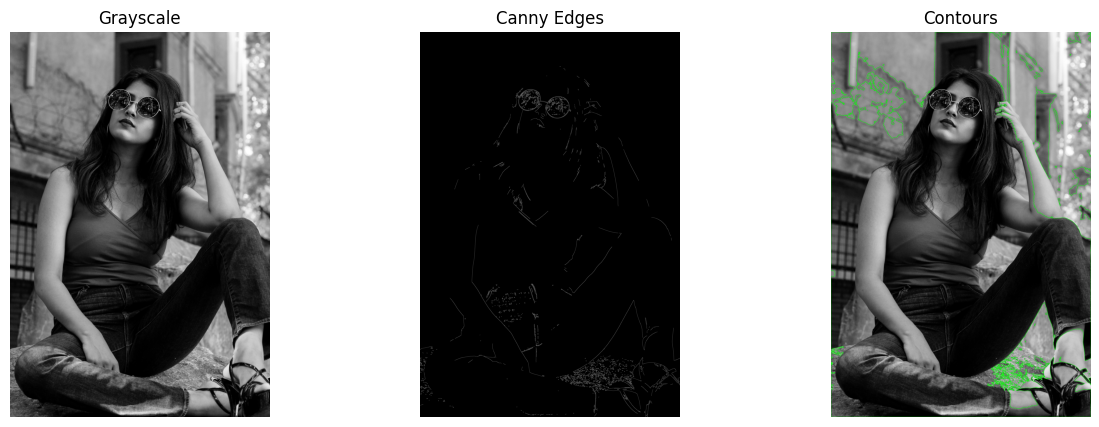

Number of contours: 599


In [3]:
import cv2
import matplotlib.pyplot as plt

# Read image
image = cv2.imread("image.jpg")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Apply Gaussian blur
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Canny edge detection
edges = cv2.Canny(blurred, 100, 200)

# Thresholding for contours
_, binary = cv2.threshold(
    blurred, 127, 255, cv2.THRESH_BINARY_INV
)

# Find contours
contours, hierarchy = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Draw contours
output = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

cv2.drawContours(
    output, contours, -1, (0, 255, 0), 2
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Contours")
plt.axis("off")

plt.show()

print("Number of contours:", len(contours))